# 10 Bias check

The gradient boosting models in 07-09 have a mean error (forecast minus actual) of about -4. Two explanations: (a) skew, because absolute-error loss targets the conditional median and the price has a long right tail, so the mean error is negative even when half the actuals are above the forecast; (b) a genuine under-forecast, for example because prices rose faster than the training data. They are told apart by the share of actual prices above the forecast (about 50% under (a)) and by the median error (near zero under (a)). Uses the saved cross-validation predictions (no refitting).

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _eval import make_folds

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
fold_of = {d: f["fold"] for f in folds for d in f["val_days"]}

P = pd.read_parquet("outputs/cv_preds_gbm_direct_0900.parquet")
P["fold"] = P["day"].map(fold_of)
PD = pd.read_parquet("outputs/cv_preds_gbm_dev_0900.parquet")[["period_start", "C dev expanding"]]
P = P.merge(PD, on="period_start", how="left")
P["hour_frac"] = P["period_start"].map(D9.set_index("period_start")["hour_frac"])
MODELS = {"28-day median (baseline)": "med28_same", "GBM direct, set C abs expanding": "C abs expanding", "GBM direct, set B abs expanding": "B abs expanding"}
print(len(P), "validation rows")

22847 validation rows


## 1. Overall

Residual = actual - forecast (positive means the forecast was too low). Reported: mean residual (= minus the bias), median residual, share of actual prices above the forecast, and the mean residual after dropping the top 1% of actual prices in each fold.

In [2]:
def summary(col):
    d = P.dropna(subset=["price", col]).copy()
    d["r"] = d["price"] - d[col]
    trimmed = d.groupby("fold", group_keys=False).apply(lambda g: g[g["price"] <= g["price"].quantile(0.99)])
    return {"mean residual": d["r"].mean(), "median residual": d["r"].median(),
            "share actual above forecast": (d["r"] > 0).mean(),
            "mean residual excl top 1% of actuals": trimmed["price"].sub(trimmed[col]).mean(),
            "mean(actual) - median(actual)": d["price"].mean() - d["price"].median()}
print(pd.DataFrame({k: summary(v) for k, v in MODELS.items()}).round(3).to_string())

                                      28-day median (baseline)  GBM direct, set C abs expanding  GBM direct, set B abs expanding
mean residual                                           -1.890                            3.588                            3.698
median residual                                          1.050                            2.810                            2.835
share actual above forecast                              0.516                            0.532                            0.530
mean residual excl top 1% of actuals                    -3.028                            2.592                            2.697
mean(actual) - median(actual)                           -3.839                           -3.835                           -3.835


## 2. By fold

If the negative bias were mostly from the level rising, it would be concentrated in the folds where prices rose. Per fold: median residual, mean residual, share of actuals above the forecast, and the change in the median price from the previous fold.

In [3]:
rows = []
for k, g in P.groupby("fold"):
    d = g.dropna(subset=["price", "C abs expanding", "med28_same", "C dev expanding"])
    rc, rb, rd = d["price"] - d["C abs expanding"], d["price"] - d["med28_same"], d["price"] - d["C dev expanding"]
    rows.append({"fold": k, "median price": d["price"].median(),
                 "model median resid": rc.median(), "model mean resid": rc.mean(), "model share above": (rc > 0).mean(),
                 "baseline mean resid": rb.mean(), "baseline share above": (rb > 0).mean(),
                 "dev-target mean resid": rd.mean(), "dev-target share above": (rd > 0).mean(),
                 "MAE model": rc.abs().mean(), "MAE dev": rd.abs().mean(), "MAE baseline": rb.abs().mean()})
F = pd.DataFrame(rows).set_index("fold")
F["price change vs prev fold"] = F["median price"].diff()
print(F.round(2).to_string())
print()
print("correlation across folds of model mean residual with the change in median price:",
      round(F["model mean resid"].corr(F["price change vs prev fold"]), 2))

      median price  model median resid  model mean resid  model share above  baseline mean resid  baseline share above  dev-target mean resid  dev-target share above  MAE model  MAE dev  MAE baseline  price change vs prev fold
fold                                                                                                                                                                                                                              
0            79.40                9.05              7.58               0.58                 1.01                  0.52                  18.49                    0.67      26.39    29.15         24.87                        NaN
1            64.68              -16.39            -14.48               0.38               -11.95                  0.43                 -13.22                    0.38      31.94    32.35         36.38                     -14.73
2            83.48               17.23             13.74               0.65                -

## 3. By time of day

Mean and median residual of the set C model and of the baseline, in blocks of the day, and the share of actuals above the forecast.

In [4]:
d = P.dropna(subset=["price", "C abs expanding", "med28_same"]).copy()
d["block"] = pd.cut(d["hour_frac"], [-0.1, 5.99, 9.99, 15.99, 19.99, 24], labels=["00-06", "06-10", "10-16", "16-20", "20-24"])
d["rc"] = d["price"] - d["C abs expanding"]; d["rb"] = d["price"] - d["med28_same"]
g = d.groupby("block", observed=True)
print(pd.DataFrame({"model mean resid": g["rc"].mean(), "model median resid": g["rc"].median(), "model share above": g["rc"].apply(lambda s: (s > 0).mean()),
                    "baseline mean resid": g["rb"].mean(), "baseline median resid": g["rb"].median(), "baseline share above": g["rb"].apply(lambda s: (s > 0).mean())}).round(2).to_string())

       model mean resid  model median resid  model share above  baseline mean resid  baseline median resid  baseline share above
block                                                                                                                           
00-06              6.49                4.46               0.56                -0.38                   1.82                  0.53
06-10              2.20                2.69               0.53                -3.47                   0.20                  0.50
10-16              1.28               -0.69               0.49                -4.27                   0.72                  0.51
16-20              4.63                4.12               0.55                -0.37                   0.47                  0.51
20-24              3.05                3.14               0.54                -0.54                   1.41                  0.52


## 4. Calibration by forecast level

If the model is a good median forecaster, in every bin of the forecast about half of the actuals should be above it. Bins are deciles of the forecast.

      mean forecast  median actual  mean actual  share actual above forecast
fbin                                                                        
0             16.15          13.54        27.62                         0.54
1             53.59          67.07        62.82                         0.63
2             68.45          77.99        74.53                         0.58
3             75.66          80.62        80.37                         0.55
4             81.01          84.16        84.22                         0.53
5             86.22          89.01        89.03                         0.53
6             91.63          92.10        92.38                         0.50
7             97.96          97.90        96.82                         0.49
8            106.06         104.40       104.40                         0.48
9            120.20         117.49       120.63                         0.48


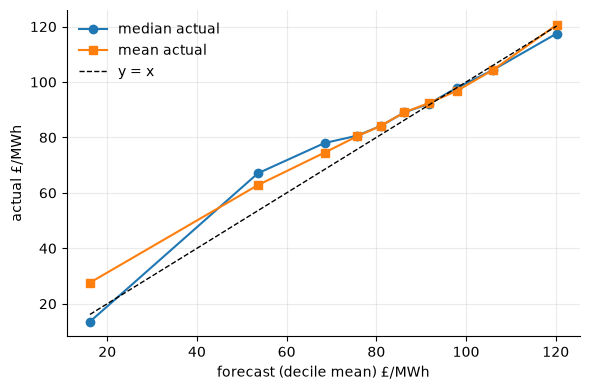

In [5]:
d["fbin"] = pd.qcut(d["C abs expanding"], 10, labels=False)
g = d.groupby("fbin")
cal = pd.DataFrame({"mean forecast": g["C abs expanding"].mean(), "median actual": g["price"].median(), "mean actual": g["price"].mean(),
                    "share actual above forecast": g["rc"].apply(lambda s: (s > 0).mean())})
print(cal.round(2).to_string())
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cal["mean forecast"], cal["median actual"], marker="o", label="median actual")
ax.plot(cal["mean forecast"], cal["mean actual"], marker="s", label="mean actual")
lo, hi = cal["mean forecast"].min(), cal["mean forecast"].max(); ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="y = x")
ax.set_xlabel("forecast (decile mean) \u00a3/MWh"); ax.set_ylabel("actual \u00a3/MWh"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Is the gain over the baseline the same in recent folds?

Per-fold difference between the set C model and the baseline (model minus baseline for MAE, so negative is better; for hit rates positive is better), and the mean over the first 13 folds against the last 4 (the folds closest to the hold-out, with median prices of about £97-118).

In [6]:
from _eval import score
rows = []
for k, g in P.groupby("fold"):
    d = g.dropna(subset=["price", "C abs expanding", "med28_same"])
    sm, sb = score(d, "C abs expanding"), score(d, "med28_same")
    rows.append({"fold": k, "dMAE": sm["MAE"] - sb["MAE"], "dRMSE": sm["RMSE"] - sb["RMSE"],
                 "dHitTop": sm["hit_top8"] - sb["hit_top8"], "dHitBot": sm["hit_bot8"] - sb["hit_bot8"]})
FD = pd.DataFrame(rows).set_index("fold")
print(FD.round(3).to_string())
print()
print("mean over folds 0-12 vs 13-16:")
print(pd.DataFrame({"folds 0-12": FD.loc[:12].mean(), "folds 13-16": FD.loc[13:].mean()}).round(3).to_string())

       dMAE   dRMSE  dHitTop  dHitBot
fold                                 
0     1.517  -1.074    0.036   -0.058
1    -4.441  -6.356    0.022    0.040
2    -4.947  -7.493    0.040    0.022
3    -0.815  -2.710    0.045    0.045
4    -0.992  -3.903    0.031    0.067
5    -4.249  -4.275    0.031    0.049
6    -6.432  -8.908    0.022    0.112
7     1.780   0.497    0.049    0.112
8     2.195   2.049    0.054   -0.013
9    -1.551  -4.293    0.009    0.036
10    0.159   0.463    0.000    0.062
11   -5.395  -7.594    0.013    0.121
12   -7.378 -12.187    0.004    0.076
13   -0.085  -0.576    0.036    0.000
14    0.362  -1.095    0.031   -0.004
15   -0.230  -1.018   -0.004    0.040
16    2.839   0.899    0.027    0.013

mean over folds 0-12 vs 13-16:
         folds 0-12  folds 13-16
dMAE         -2.350        0.721
dRMSE        -4.291       -0.448
dHitTop       0.027        0.022
dHitBot       0.052        0.012


## Findings

- **The skew explanation is rejected.** In the validation days the mean price is 3.8 *below* the median (negative prices pull the mean down), so skew would make the mean error go the other way. The set C model's median error is +3.2 (actual above forecast), and 53.5% of actual prices are above its forecast (baseline: 51.6%). Excluding the top 1% of actual prices in each fold leaves a mean error of +3.0. The under-forecast is real, about 3-4 pounds on average.
- **It is concentrated in the folds where prices rose.** The mean error by fold swings from -15 to +24, and its correlation with the change in the median price from the previous fold is 0.65. In folds 11-16 the share of actuals above the forecast is 0.61-0.77. In fold 16 (2026-07-09 to 2026-08-05, median price 118) the set C model under-forecasts by 23.8 on average with 77% of actuals above its forecast; the baseline under-forecasts by 6.8. The deviation-target model (08) does not fix it (+19.4, 73%).
- **The gain over the baseline is not present in the most recent folds.** Over folds 0-12 the model's MAE is 2.4 lower than the baseline's, RMSE 4.4 lower, top-8 hit +0.030 and bottom-8 +0.051. Over folds 13-16 (median prices about 97-118, nearest the hold-out) MAE is 1.0 *higher*, RMSE unchanged (-0.06), top-8 hit +0.015 and bottom-8 +0.006. With four folds and a spread of several pounds per fold this is not conclusive, but it is the regime the hold-out is in. It changes the reading of notebooks 07-09: the improvement is robust to model settings and seed, but not demonstrated to be robust to the price regime.
- **By time of day** the under-forecast is largest overnight (mean error +6.9 for 00-06) and in the evening (+4.8 for 16-20), and near zero at midday (+1.8, median -0.6).
- **By forecast level** (deciles of the forecast), 55-63% of actuals lie above the forecast in the 2nd to 5th deciles, and close to 50% in the top four. The top decile is well calibrated in level.
- **Implication.** The tree models do not adapt to a rising price level: the level features (`level24h`, `level_gap`) have about zero importance, and expanding or sliding windows plus the deviation target did not fix it. Options to test next: weighting recent training days more heavily; a model with an explicit level term (linear or regularised linear on the deviation from the profile) that can extrapolate; and an adjustment of the profile by a recent, smoother price level (the crude version in notebook 04 did not help, but a better one is possible). Whichever is used, the comparison against the baseline must be reported separately for the recent folds.
